# Diffusion models, Lecture 3: latent diffusion and text-to-image

**Problem.** In Lectures 1 and 2 we generated 28 × 28 digits and 32 × 32 CIFAR-10 images. Producing 16 small CIFAR-10 images already took about a minute. Two things stand between those models and a system that turns a sentence such as *"a watercolor painting of a lighthouse at sunset"* into a 512 × 512 picture:

1. **Size.** A 512 × 512 colour image has 786,432 numbers. Running a large U-Net on all of them at every one of many denoising steps is expensive to train and slow to sample.
2. **The condition.** In Lecture 2 the condition was one of 10 class labels. A sentence can describe almost anything, so the condition must be a rich representation of text, and the network must be able to look up different words for different parts of the image.

**Latent diffusion** (Rombach et al., 2022) answers both. An autoencoder compresses the image to a much smaller **latent**, the diffusion process of Lectures 1 and 2 runs on that latent, and a text encoder turns the prompt into a sequence of vectors that the U-Net reads through **cross-attention**. Stable Diffusion is the best-known model built this way, and it is the one we take apart in this lecture.

**What you will learn**

1. Why diffusion in **latent space** is far cheaper than diffusion on pixels, and what the autoencoder gives up in exchange.
2. How a prompt becomes **text embeddings**, and how **cross-attention** lets image features use them.
3. How the full text-to-image **sampling loop** is assembled from pieces you already know: DDIM steps, classifier-free guidance, and a decoder at the end.
4. How the **guidance scale, step count, seed and prompt** change the result.
5. How the same machinery **edits an existing image** (SDEdit, also called image-to-image).
6. What this model **cannot** do well, and the data, bias and misuse questions it raises.

**Prerequisites:** Lectures 1a and 1b ([Lecture 1a](lecture1a_forward_process.ipynb) and [Lecture 1b](lecture1b_learning_to_denoise.ipynb): the forward equation $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$, noise prediction, sampling) and [Lecture 2](lecture2_better_faster.ipynb) (conditioning, dropping the condition during training, classifier-free guidance, DDIM). The Module 1 lecture on variational autoencoders helps with Section 3.

**Setup and downloads.** Run on **Kaggle with a T4 GPU and internet on**, once before class. We do not train anything; every section uses a pretrained model.

| Section | What | Download | Licence |
| --- | --- | ---: | --- |
| 2 | [`stable-diffusion-v1-5/stable-diffusion-v1-5`](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5), half-precision weights: U-Net 1.72 GB, safety checker 0.61 GB, text encoder 0.25 GB, autoencoder 0.17 GB | about 2.7 GB | CreativeML OpenRAIL-M |
| 3, 7 | `coffee` test photograph, bundled with `scikit-image` | none | CC0 (photographer Rachel Michetti) |

The model repository is a community mirror of the original Stable Diffusion v1.5 release, which has been withdrawn from its first location. No Hugging Face account is needed. A GPU is needed in practice: the notebook also runs on a CPU, but there one image takes minutes.

**About the saved outputs.** The outputs and the numbers quoted in the "Reading the output" notes come from one run on a Kaggle T4 GPU (PyTorch 2.11, diffusers 0.40, transformers 5.16) on 17 October 2026. A rerun gives slightly different numbers and can give different images, even with the same seeds, because GPU arithmetic is not exactly reproducible and library versions change.

In [1]:
import math
import subprocess
import sys
import time

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torchvision
from skimage import data as skdata

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32      # half precision on the GPU halves memory and time
torch.manual_seed(0)
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", DEVICE)
if DEVICE == "cpu":
    print("No GPU found. Sections 2-8 will be very slow; one image takes minutes on a CPU.")


def to_display(x):
    """Images in [-1, 1] -> [0, 1] for plotting."""
    return ((x.detach().float().cpu() + 1) / 2).clamp(0, 1)


def show_row(images, titles=None, size=3.0, suptitle=None):
    """One row of images, each (3, H, W) in [-1, 1]."""
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=(size * n, size * 1.12))
    for i, ax in enumerate(axes if n > 1 else [axes]):
        ax.imshow(to_display(images[i]).permute(1, 2, 0))
        ax.axis("off")
        if titles:
            ax.set_title(titles[i], fontsize=9)
    if suptitle:
        fig.suptitle(suptitle, fontsize=11)
    plt.tight_layout(); plt.show()


def sync():
    if DEVICE == "cuda":
        torch.cuda.synchronize()

PyTorch 2.11.0+cu128 | torchvision 0.26.0+cu128 | device: cuda


## 1. Why not run diffusion on pixels?

A diffusion model calls its U-Net once per denoising step, and the cost of each call grows with the number of values it processes. Compare a 512 × 512 colour image with the latent that Stable Diffusion uses for the same image: the autoencoder shrinks height and width by a factor of 8 and keeps 4 channels.

The second comparison matters even more. The U-Net contains **attention layers** (Section 4), in which every position compares itself with every other position, so their cost grows with the **square** of the number of positions.

In [2]:
H = W = 512
pixel_values = 3 * H * W
latent_values = 4 * (H // 8) * (W // 8)
print(f"pixels: 3 x {H} x {W}            = {pixel_values:>9,} values")
print(f"latent: 4 x {H // 8} x {W // 8}              = {latent_values:>9,} values   ({pixel_values / latent_values:.0f}x fewer)")

pixel_positions, latent_positions = H * W, (H // 8) * (W // 8)
print(f"\nattention over every pixel position : {pixel_positions:>7,}^2 = {pixel_positions**2:.1e} pairs")
print(f"attention over every latent position: {latent_positions:>7,}^2 = {latent_positions**2:.1e} pairs "
      f"({pixel_positions**2 / latent_positions**2:,.0f}x fewer)")

pixels: 3 x 512 x 512            =   786,432 values
latent: 4 x 64 x 64              =    16,384 values   (48x fewer)

attention over every pixel position : 262,144^2 = 6.9e+10 pairs
attention over every latent position:   4,096^2 = 1.7e+07 pairs (4,096x fewer)


**Reading the output.** The latent has 48 times fewer values than the image. Full attention over its 4,096 positions needs 4,096 times fewer comparisons than attention over all 262,144 pixels: about 17 million pairs instead of 69 billion. That is the whole argument for latent diffusion: **do the expensive, many-step work on a small representation, and convert to pixels only once, at the end.**

The price is that the result can only be as good as the autoencoder's reconstruction, and Section 3 looks at that.

Rombach et al. (2022) put it this way: most of the bits in an image are imperceptible detail. An autoencoder can take care of that detail, while the diffusion model spends its capacity on the content and composition that matter.

```text
                 training, and image editing (Section 7)           every sampling step
 image ──► [ encoder ] ──► latent z₀ ──► add noise ──► z_t ──► [ U-Net ] ──► predicted noise
 512×512×3                  64×64×4                               ▲
                                                prompt ──► [ text encoder ] ──► 77 × 768 embeddings
 sampling:  random z_T ──► (U-Net, many steps) ──► z₀ ──► [ decoder ] ──► 512×512×3 image
```

## 2. The pieces of Stable Diffusion

Stable Diffusion v1.5 is not one network but **four**, trained separately and loaded together.

| Component | Job | Trained on |
| --- | --- | --- |
| **Autoencoder** (a VAE) | encoder: image → latent; decoder: latent → image | images only |
| **Text encoder** (CLIP ViT-L/14) | prompt → 77 vectors of 768 numbers | image–caption pairs (by OpenAI, then frozen) |
| **U-Net** | predicts the noise in a latent, given the time step and the text vectors | latents of LAION image–caption pairs |
| **Safety checker** | flags generated images that match a list of unsafe concepts | a separate CLIP-based classifier |

Only the U-Net is a diffusion model. The autoencoder and the text encoder were trained first and then **frozen**, so the U-Net learned to work in the autoencoder's latent space and to read the text encoder's vectors.

According to the [model card](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5), the U-Net was trained with the text condition dropped **10% of the time**. That is the "no label" trick of Lecture 2, and it is what makes classifier-free guidance possible here too.

We load everything with the Hugging Face `diffusers` library. We replace the default sampler with **DDIM** from Lecture 2, so every step of the loop in Section 5 is one you have seen before.

> **Download:** the next cell installs `diffusers` if it is missing and downloads about 2.7 GB of weights into the Hugging Face cache. The first run takes a few minutes; later runs reuse the cache. Warnings about unauthenticated requests can be ignored.

In [3]:
try:
    import diffusers
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "diffusers"])
    import diffusers
import transformers
from diffusers import DDIMScheduler, StableDiffusionPipeline

print("diffusers", diffusers.__version__, "| transformers", transformers.__version__)

MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, torch_dtype=DTYPE, variant="fp16").to(DEVICE)
pipe.set_progress_bar_config(disable=True)
pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)    # same noise schedule, DDIM update rule

vae, tokenizer, text_encoder, unet, scheduler = pipe.vae, pipe.tokenizer, pipe.text_encoder, pipe.unet, pipe.scheduler
SCALE = vae.config.scaling_factor                                     # explained in Section 3


def n_params(module):
    return sum(p.numel() for p in module.parameters())


for name, module in [("autoencoder (VAE)", vae), ("text encoder (CLIP)", text_encoder),
                     ("U-Net (denoiser)", unet), ("safety checker", pipe.safety_checker)]:
    print(f"{name:20s} {n_params(module) / 1e6:7.1f} million parameters")
print("\nnoise schedule:", scheduler.config.beta_schedule, "| beta from", scheduler.config.beta_start,
      "to", scheduler.config.beta_end, "| T =", scheduler.config.num_train_timesteps)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


diffusers 0.40.0 | transformers 5.16.1


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

autoencoder (VAE)       83.7 million parameters
text encoder (CLIP)    123.1 million parameters
U-Net (denoiser)       859.5 million parameters
safety checker         304.0 million parameters

noise schedule: scaled_linear | beta from 0.00085 to 0.012 | T = 1000


**Reading the output.** The four parts have:

| Part | Parameters |
| --- | ---: |
| U-Net | 859.5 million |
| Safety checker | 304.0 million |
| Text encoder | 123.1 million |
| Autoencoder | 83.7 million |

The U-Net has by far the most parameters. It is also the only part that runs at every step, so it is where the time goes. The download messages and warnings above the table (a `FutureWarning` about `torch_dtype`, a note about unauthenticated requests) do not affect the results.

The noise schedule is again $T = 1000$ steps, but the $\beta$ values differ from Lecture 1's linear 0.0001 → 0.02. The "scaled linear" schedule spaces $\sqrt{\beta}$ evenly between the two printed end points. The idea is unchanged: a fixed recipe for how fast the signal fades.

## 3. The autoencoder: from pixels to latents and back

Stable Diffusion's autoencoder is a **variational autoencoder (VAE)**, the same kind of model as in Module 1. Its two halves are both part of the one model, `vae`:

| Half | Maps | Shapes | Called as | When it runs |
| --- | --- | --- | --- | --- |
| **Encoder** | image $x$ → a mean and a variance for each latent value | (3, 512, 512) → (4, 64, 64) | `vae.encode(x).latent_dist.mean` | Only when a real image must become a latent: training the U-Net, and image editing (Section 7) |
| **Decoder** | latent $z$ → image | (4, 64, 64) → (3, 512, 512) | `vae.decode(z)` | Once, at the end of every generation |

We use only the encoder's **mean**, never a sample, so here the encoder always gives the same latent for the same image.

**What its training loss uses.** Unlike the small VAEs of Module 1, it combines:

- **Pixel loss:** the reconstruction should match the original pixel by pixel.
- **Perceptual loss:** compares features from a pretrained network, so the reconstruction *looks* like the original, not just matches it on average.
- **Adversarial (GAN) loss:** a discriminator penalises blurry or unrealistic detail, so reconstructions stay sharp instead of blurry.
- **KL term, with a very small weight:** only keeps the latent values in a sensible range. It does not make the latent space smooth enough to sample from: in latent diffusion the diffusion model does the generating, not the VAE.

One detail: the raw latent values have a standard deviation well above 1. The diffusion process assumes data of roughly unit scale, the same scale as the noise added to it. So the latents are multiplied by a fixed **scaling factor** before diffusion, and divided by it again before decoding.

We test the autoencoder on a photograph that comes with `scikit-image`. It shows a coffee cup on a wooden table and is released under CC0.

image  : (1, 3, 512, 512) -> 786,432 values
latent : (1, 4, 64, 64) -> 16,384 values
latent std before scaling 5.28, scaling factor 0.18215, after scaling 0.96
reconstruction: mean squared error 0.0029, PSNR 31.4 dB


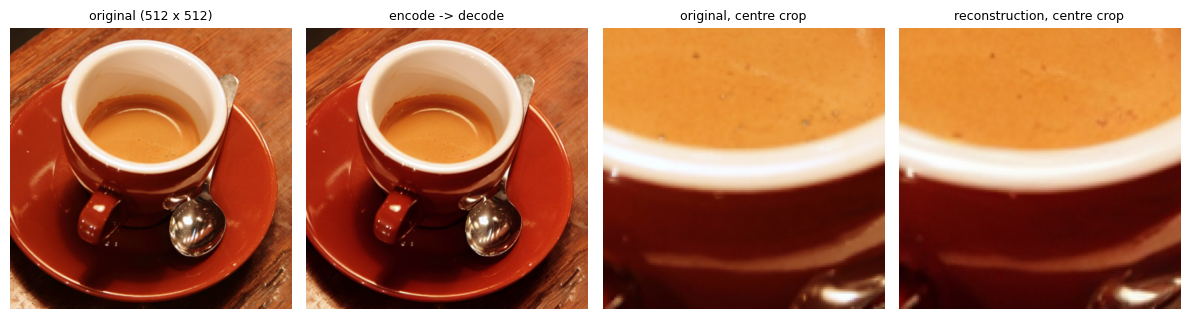

In [4]:
# Load the photo as a NumPy array of shape (400, 600, 3), uint8 values 0-255 (height, width, RGB),
# and keep columns 100-499: a square 400 x 400 centre crop around the cup.
photo = skdata.coffee()[:, 100:500]
# To a tensor, channels first as PyTorch expects: (3, 400, 400). Dividing by 127.5 and subtracting 1
# maps 0-255 to [-1, 1], the pixel range the autoencoder was trained on.
x = torch.from_numpy(photo).permute(2, 0, 1).float() / 127.5 - 1
# Resize to the 512 x 512 the model was trained at. x[None] adds a batch dimension, (1, 3, 400, 400),
# because interpolate expects a batch. (antialias=True only matters when shrinking an image; here we enlarge it.)
x = F.interpolate(x[None], size=(512, 512), mode="bilinear", antialias=True, align_corners=False)
# Clip to [-1, 1] as a safeguard (bilinear resizing only averages neighbouring pixels, so values should already
# be in range); then move to the GPU in the model's precision (half precision on the GPU). Shape (1, 3, 512, 512).
x = x.clamp(-1, 1).to(DEVICE, DTYPE)

# No training here, so skip gradient tracking: it saves memory and time.
with torch.no_grad():
    # Encode: the encoder returns a distribution (a mean and a variance per latent value); we take its mean.
    # Shape (1, 4, 64, 64).
    z_raw = vae.encode(x).latent_dist.mean
    # Multiply by the fixed scaling factor (0.18215) so the latent has roughly unit scale,
    # the scale the diffusion model works with.
    z0 = z_raw * SCALE
    # Decode: undo the scaling, decode back to an image of shape (1, 3, 512, 512), and clip to [-1, 1].
    x_rec = vae.decode(z0 / SCALE).sample.clamp(-1, 1)

print("image  :", tuple(x.shape), "->", f"{x.numel():,} values")
print("latent :", tuple(z0.shape), "->", f"{z0.numel():,} values")
print(f"latent std before scaling {z_raw.float().std():.2f}, scaling factor {SCALE}, after scaling {z0.float().std():.2f}")

mse = F.mse_loss(x_rec.float(), x.float()).item()
psnr = 10 * math.log10(4 / mse)                                   # pixel range is 2 (from -1 to 1), so peak^2 = 4
print(f"reconstruction: mean squared error {mse:.4f}, PSNR {psnr:.1f} dB")

c = slice(192, 320)                                               # a 128 x 128 crop from the centre, to see detail
show_row([x[0], x_rec[0], x[0, :, c, c], x_rec[0, :, c, c]],
         ["original (512 x 512)", "encode -> decode", "original, centre crop", "reconstruction, centre crop"])

**Reading the output.**

- **Shapes:** the 786,432 pixel values become 16,384 latent values.
- **Scaling factor:** the raw latent's standard deviation is 5.28. Multiplying by 0.18215 brings it to 0.96, close to the unit scale the diffusion process expects.
- **The full images** are almost indistinguishable: the autoencoder keeps the content, colours and layout.
- **The centre crops** are where to look for losses. Here they are small: the dark specks in the coffee survive, slightly softened. The model card nevertheless says plainly that "the autoencoding part of the model is lossy". Small text, faces and fine regular patterns are the usual casualties; this photograph has none of those.
- **PSNR:** in our run the mean squared error was 0.0029, a PSNR of 31.4 dB. PSNR (peak signal-to-noise ratio) is a standard way to report reconstruction error in decibels; higher is better. It measures how close the pixels are, not how good the image looks.

Every image Stable Diffusion produces passes through this decoder. Whatever the decoder cannot draw, the model cannot produce, however good the U-Net is.

Next, what a latent looks like, and what the decoder makes of a latent that the encoder did not produce.

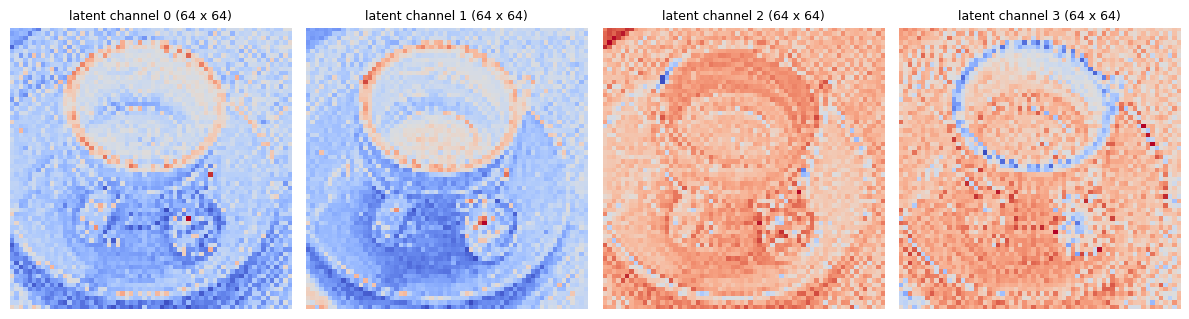

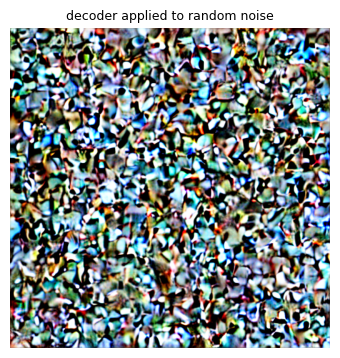

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3))
for ch in range(4):
    axes[ch].imshow(z0[0, ch].float().cpu(), cmap="coolwarm")
    axes[ch].set_title(f"latent channel {ch} (64 x 64)", fontsize=9); axes[ch].axis("off")
plt.tight_layout(); plt.show()

with torch.no_grad():
    # A latent the encoder did not produce: standard Gaussian noise with the same shape as the photo's latent, (1, 4, 64, 64).
    # Like z0 after scaling, it has unit scale, so it is what a diffusion model starts from (seeded so reruns give the same noise).
    z_random = torch.randn(z0.shape, generator=torch.Generator(DEVICE).manual_seed(0), device=DEVICE, dtype=DTYPE)
    # Decode it exactly as we decoded the photo's latent: divide by SCALE to undo the scaling, decode to (1, 3, 512, 512),
    # and clip to the image range [-1, 1].
    x_random = vae.decode(z_random / SCALE).sample.clamp(-1, 1)
show_row([x_random[0]], ["decoder applied to random noise"], size=3.5)

**Reading the output.**

- **The four channels** all show the cup, saucer and handle at 1/8 resolution, each with different contrast. Channels 0 and 1 look alike, and channel 3 picks out the rim. The latent is not a small picture, though: the channels do not correspond to colours, and only the decoder knows how to turn them back into pixels.
- **The decoder fed random numbers** gives a dense, colourful, high-frequency texture with no objects at all. The decoder only makes sense of latents that look like the ones the encoder produces. **Producing such latents from noise is exactly the job of the diffusion model.**

Finally, the forward process of Lecture 1 runs unchanged in latent space. We use the noise schedule of Stable Diffusion and decode each noisy latent so we can see it.

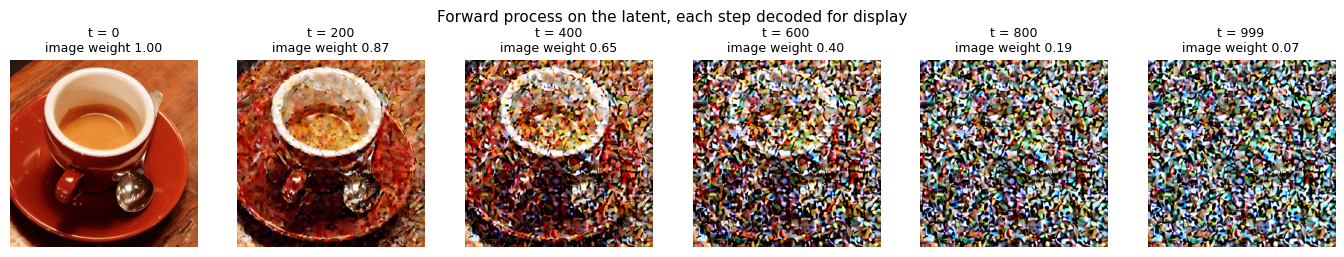

In [ ]:
# add noise to the cup latent z0 at various timesteps, decoding each noisy latent to see the effect of the forward diffusion process
noise = torch.randn(z0.shape, generator=torch.Generator(DEVICE).manual_seed(1), device=DEVICE, dtype=DTYPE)
steps_to_show = [0, 200, 400, 600, 800, 999]
noisy_images = []
with torch.no_grad():
    for t in steps_to_show:
        z_t = scheduler.add_noise(z0, noise, torch.tensor([t], device=DEVICE))   # sqrt(abar_t) z0 + sqrt(1 - abar_t) eps
        noisy_images.append(vae.decode(z_t / SCALE).sample.clamp(-1, 1)[0])
abar = scheduler.alphas_cumprod
show_row(noisy_images, [f"t = {t}\nimage weight {abar[t].sqrt():.2f}" for t in steps_to_show], size=2.3,
         suptitle="Forward process on the latent, each step decoded for display")

**Reading the output.** The equation is the one from Lecture 1, $z_t = \sqrt{\bar\alpha_t}\,z_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$, applied to the latent instead of the pixels. As $t$ grows, the decoded cup dissolves into the same texture we saw for pure noise. The rim of the cup is still visible at $t = 600$ and faintly at $t = 800$.

## 4. From a prompt to text embeddings, and cross-attention

### 4.1 Tokens and embeddings

The text encoder is the text half of **CLIP** (Radford et al., 2021). CLIP (Contrastive Language–Image Pre-training) was trained to match images with their captions, so its text vectors carry visual meaning: "sunset" lies near the concepts that appear in pictures of sunsets.

**CLIP's two halves.** Each encoder takes one kind of input and returns one vector, and both vectors live in the same space.

| | Image encoder | Text encoder |
| --- | --- | --- |
| **Input** | An RGB image, resized and cropped to a fixed size (224 × 224 for ViT-L/14) | A piece of text, split into tokens and padded or cut to 77 tokens |
| **Network** | Vision Transformer (or ResNet in some versions) | Transformer |
| **Output** | One embedding vector, e.g. 768 numbers for ViT-L/14 | One embedding vector of the same size, 768 for ViT-L/14 |

**How the two outputs are used.**

| Step | What happens |
| --- | --- |
| 1. Normalise | Scale both vectors to length 1. |
| 2. Compare | Take their dot product, which is the cosine similarity. A high value means the text describes the image. |
| 3. Train | With $N$ images and $N$ captions, the similarities form an $N \times N$ matrix. Training pushes the diagonal (true pairs) up and everything else down: this is the "contrastive" in the name. |

**Typical uses.**

| Use | How it works |
| --- | --- |
| Zero-shot classification | Encode one image and one sentence per class ("a photo of a dog.", "a photo of a cat."); the most similar sentence is the predicted class, with no labelled training images. |
| Retrieval | Find images for a text, or texts for an image, by ranking similarities. |
| Component of another model | Use one encoder alone, as Stable Diffusion does with the text encoder (frozen). |

Stable Diffusion does not use CLIP's single output vector. Inside, the text encoder produces one vector per token (77 × 768); CLIP's summary vector is taken at the end-of-text token. Stable Diffusion uses all 77 per-token vectors, so that cross-attention (Section 4.2) can link image regions to individual words.

The prompt is first split into **tokens**: whole words or pieces of words. Two markers are added, `<|startoftext|>` at the start and `<|endoftext|>` at the end. The sequence is then padded to a fixed length of **77**. The encoder turns each of the 77 positions into a vector of 768 numbers. Because it is a transformer, each vector depends on the whole prompt, not only on its own token.

In [7]:
PROMPT = "a watercolor painting of a lighthouse on a cliff at sunset"
tok = tokenizer(PROMPT, padding="max_length", max_length=tokenizer.model_max_length,
                truncation=True, return_tensors="pt")
n_real = int(tok.attention_mask[0].sum())
print("sequence length:", tokenizer.model_max_length, "| tokens from the prompt incl. start/end markers:", n_real)
print(tokenizer.convert_ids_to_tokens(tok.input_ids[0, :n_real + 2].tolist()), "... (padding)")

with torch.no_grad():
    text_emb = text_encoder(tok.input_ids.to(DEVICE))[0]
print("text embeddings:", tuple(text_emb.shape), " (batch, positions, numbers per position)")

long_prompt = ", ".join(["a tall white lighthouse"] * 20)
print("\na 20-times repeated phrase has", len(tokenizer(long_prompt).input_ids),
      f"tokens; everything after position {tokenizer.model_max_length} is cut off")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (101 > 77). Running this sequence through the model will result in indexing errors


sequence length: 77 | tokens from the prompt incl. start/end markers: 13
['<|startoftext|>', 'a</w>', 'watercolor</w>', 'painting</w>', 'of</w>', 'a</w>', 'lighthouse</w>', 'on</w>', 'a</w>', 'cliff</w>', 'at</w>', 'sunset</w>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>'] ... (padding)
text embeddings: (1, 77, 768)  (batch, positions, numbers per position)

a 20-times repeated phrase has 101 tokens; everything after position 77 is cut off


**Reading the output.** Our prompt became 13 tokens: the start marker, 11 words, and the end marker. Every word here is common enough to be a single token, marked `</w>` for "end of word". A rarer word would be split into several pieces, with the marker only on the last. The remaining 64 positions are padding. The embedding tensor has shape (1, 77, 768) whatever the prompt length.

The repeated phrase needs 101 tokens, so its last 24 are **truncated**: the end of a long prompt has no effect on the image. The tokenizer's warning about "101 > 77" at the top of the output says the same thing.

### 4.2 Cross-attention: how the image reads the text

In Lecture 2 the condition was a single label embedding, **added** to the time embedding: one vector, applied everywhere in the image in the same way. A prompt is 77 vectors, and different parts of the image need different words: the lighthouse region needs "lighthouse", the sky needs "sunset". **Cross-attention** lets each image position choose.

- Each position of the U-Net's feature map forms a **query** $q$: "what am I looking for?"
- Each text vector forms a **key** $k$ ("what do I offer?") and a **value** $v$ ("what I will pass on").
- Each position compares its query with all 77 keys, turns the scores into weights with a softmax, and takes the weighted average of the values:

$$\text{CrossAttention}(Q, K, V) = \operatorname{softmax}\!\left(\frac{Q K^\top}{\sqrt{d}}\right) V, \qquad Q \text{ from the image}, \quad K, V \text{ from the text}.$$

Shapes: with $N$ image positions, $L$ text positions and width $d$, $Q$ is $(N, d)$ and $K, V$ are $(L, d)$. The weight matrix is $(N, L)$: one row per image position, summing to 1. The output is $(N, d)$, one updated feature per image position. **Self-attention**, which the U-Net also uses, is the same formula with $Q$, $K$ and $V$ all taken from the image.

The figure shows where these layers sit in Stable Diffusion's U-Net. The prompt is encoded once, and its 77 text vectors feed every block that contains transformer blocks.

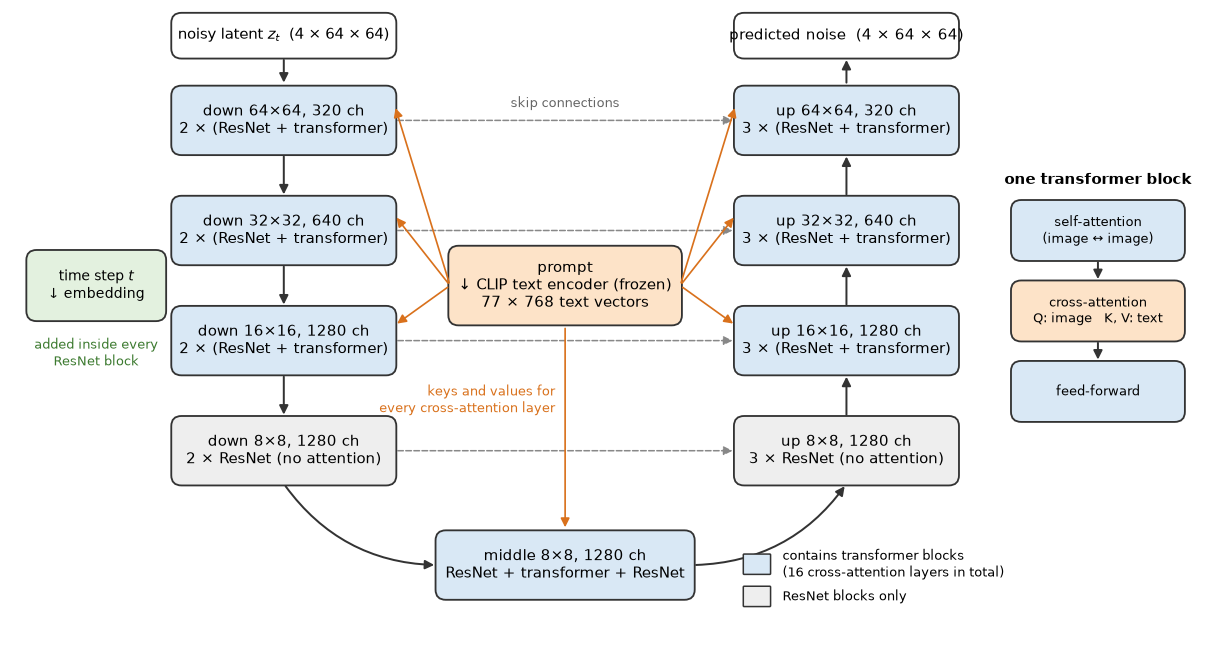

Each down or up block in the figure is a container. The transformer blocks are **separate** from the ResNet blocks: inside a block the two alternate.

| Block | Contents, in order |
| --- | --- |
| Down 64, 32, 16 | ResNet → Transformer → ResNet → Transformer → **downsample** |
| Down 8 | ResNet → ResNet (no attention, no downsample) |
| Middle 8 | ResNet → Transformer → ResNet |
| Up 8 | ResNet → ResNet → ResNet → **upsample** (no attention) |
| Up 16, 32, 64 | ResNet → Transformer, three times → **upsample** (except the last block) |

In the up blocks, each ResNet block first concatenates a skip connection from the matching down level. The two kinds of block do different jobs:

| Part | Mixes information across | Gets the condition |
| --- | --- | --- |
| **ResNet block** (convolutions + residual) | Nearby positions, through 3 × 3 kernels | **Time step**: its embedding is added to the features |
| **Transformer block** (self-attn → cross-attn → feed-forward) | All positions (self-attention) and the text (cross-attention) | **Text**: the 77 vectors are its keys and values |

So in each pair, the ResNet block processes local features together with the time step, and the transformer block then lets every position look at the whole image and at the prompt. Both add their result back to the features through a residual connection.

Each cross-attention layer sits inside a small **transformer block** of the U-Net: self-attention (image positions attend to each other), then cross-attention (image positions attend to the text), then a feed-forward layer. Here is one cross-attention layer of the real model, at the 64 × 64 level of the latent, where the feature map has 320 channels:

| | Comes from | Shape |
| --- | --- | --- |
| Queries $Q$ | The U-Net's feature map, flattened | 4096 positions × 320 |
| Keys $K$, values $V$ | The CLIP text vectors, projected from 768 to 320 | 77 × 320 |
| Attention weights | $\operatorname{softmax}(QK^\top/\sqrt{d})$ | 4096 × 77, one row per image position |
| Output | Weights × $V$, added back to the feature map | 4096 × 320 |

The same 77 × 768 text vectors go into all 16 cross-attention layers of the U-Net at every denoising step; each layer has its own learned projections, so each reads them differently. The time step does not use cross-attention: it is added as an embedding, as the label was in Lecture 2.

**Self-attention in the same block.** Before cross-attention reads the text, self-attention lets the image positions read each other. At the 64 × 64 level, each of the 4096 positions attends to all 4096 positions, including itself. For one position:

1. Its query is compared with all 4096 keys, giving 4096 weights that sum to 1.
2. Those weights mix the 4096 value vectors into one 320-number vector.
3. That vector is added to the position's features.

Each position therefore gets **global context**: information from anywhere in the image, not just from the 3 × 3 neighbourhood a convolution sees.

Here is cross-attention with tiny random numbers: 6 image positions, 3 text tokens, width 4.

In [8]:
torch.manual_seed(0)
d = 4
image_features = torch.randn(6, d)                    # N = 6 positions of a feature map
text_features = torch.randn(3, d)                     # L = 3 text tokens
W_q, W_k, W_v = (torch.randn(d, d) for _ in range(3)) # learned projections in a real model

Q, K, V = image_features @ W_q, text_features @ W_k, text_features @ W_v
weights = torch.softmax(Q @ K.T / math.sqrt(d), dim=-1)   # (6, 3): how much each position uses each token
out = weights @ V                                         # (6, 4): text information delivered to each position
print("Q", tuple(Q.shape), "| K", tuple(K.shape), "| V", tuple(V.shape), "| weights", tuple(weights.shape), "| out", tuple(out.shape))
print("attention weights (rows: image positions, columns: tokens)\n", weights.round(decimals=2))
print("row sums:", weights.sum(-1).round(decimals=3).tolist())

cross_layers = [name for name, _ in unet.named_modules() if name.endswith("attn2")]   # diffusers names cross-attention "attn2"
print(f"\nThe real U-Net has {len(cross_layers)} cross-attention layers, e.g. {cross_layers[0]}")
print("text vector width the U-Net expects:", unet.config.cross_attention_dim)

Q (6, 4) | K (3, 4) | V (3, 4) | weights (6, 3) | out (6, 4)
attention weights (rows: image positions, columns: tokens)
 tensor([[0.0000, 1.0000, 0.0000],
        [0.0500, 0.8900, 0.0600],
        [0.6700, 0.0800, 0.2500],
        [0.2300, 0.0000, 0.7700],
        [0.3400, 0.0000, 0.6600],
        [0.0000, 1.0000, 0.0000]])
row sums: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

The real U-Net has 16 cross-attention layers, e.g. down_blocks.0.attentions.0.transformer_blocks.0.attn2
text vector width the U-Net expects: 768


**Reading the output.** Each row of the weight matrix is one image position's choice among the three tokens, and each row sums to 1.

Different rows put their weight on different tokens. Positions 1 and 6 take everything from token 2, position 3 mostly uses token 1, and positions 4 and 5 mostly use token 3. That is what lets one region follow one word and another region a different word.

The real U-Net has 16 cross-attention layers at several resolutions of the feature map, so the prompt can influence both the overall layout (low resolution) and the details (high resolution). The 768 printed at the end matches the width of the CLIP text vectors.

Cross-attention lets the image **use** the text; it does not guarantee that every word is drawn correctly. Section 8 shows some failures.

## 5. Text-to-image, step by step

We now have every piece. The sampling loop below is written out by hand, and every line is something from Lectures 1 and 2:

1. **Encode** the prompt, and also an **empty prompt** `""`. The empty prompt plays the role of Lecture 2's "no label".
2. **Start** from Gaussian noise in latent space, shape (1, 4, 64, 64), with a seeded generator.
3. **For each** of a few dozen DDIM time steps:
   - run the U-Net once on a batch of two, with the prompt and without it;
   - combine the two predictions with **classifier-free guidance**, $\hat\epsilon = \hat\epsilon_{\text{uncond}} + w(\hat\epsilon_{\text{text}} - \hat\epsilon_{\text{uncond}})$;
   - take one **DDIM step**: estimate the clean latent $\hat z_0$, then re-noise it to the next, lower noise level.
4. **Decode** the final latent to pixels, once.
5. **Check** the image with the safety checker. It replaces a flagged image with a blank one.

The guidance scale $w$ is the same quantity as in Lecture 2: $w = 0$ ignores the prompt, $w = 1$ is plain conditioning, and $w > 1$ pushes harder towards the prompt. For this model, values around 7.5 are the common default.

In [9]:
@torch.no_grad()
def encode_text(prompts):
    """Turn prompts into CLIP text embeddings.

    Args:
        prompts: list of strings, one per image.

    Returns:
        Tensor of shape (len(prompts), 77, 768): one 768-number vector per token position.
    """
    # Split each prompt into tokens, add the start/end markers, pad to 77 positions and cut off anything longer.
    tok = tokenizer(prompts, padding="max_length", max_length=tokenizer.model_max_length,
                    truncation=True, return_tensors="pt")
    # Run the frozen CLIP text encoder; [0] is the last hidden state, the per-token vectors the U-Net attends to.
    return text_encoder(tok.input_ids.to(DEVICE))[0]


def initial_noise(seeds, height=512, width=512):
    """Draw the starting latents z_T, one per seed.

    Args:
        seeds: list of integers; the same seed always gives the same noise.
        height, width: size of the final image in pixels (the latent is 8 times smaller).

    Returns:
        Tensor of shape (len(seeds), 4, height/8, width/8) with standard Gaussian values.
    """
    # Shape of one latent: batch 1, 4 channels, and the image size divided by 8 (the autoencoder's downsampling).
    shape = (1, unet.config.in_channels, height // 8, width // 8)
    # Draw one latent per seed with its own seeded generator, then stack them along the batch dimension.
    return torch.cat([torch.randn(shape, generator=torch.Generator(DEVICE).manual_seed(s), device=DEVICE, dtype=DTYPE)
                      for s in seeds])


@torch.no_grad()
def denoise(latents, prompts, steps=30, guidance=7.5, negative="", start=0, previews=None):
    """Run the DDIM sampling loop with classifier-free guidance.

    Args:
        latents: starting latents, shape (n, 4, 64, 64): pure noise, or a noisy latent when start > 0 (SDEdit).
        prompts: one string for all n latents, or a list of n strings.
        steps: number of DDIM steps the 1000 training time steps are reduced to.
        guidance: guidance scale w; 1 means no guidance, larger values follow the prompt more strongly.
        negative: prompt for the "unconditional" prediction; the empty prompt by default.
        start: index of the first step to run; earlier steps are skipped (used by SDEdit).
        previews: optional list; if given, each step's estimate of the clean latent is appended to it.

    Returns:
        The final clean latents z_0, same shape as `latents`.
    """
    # Number of images being generated.
    n = latents.shape[0]
    # Repeat a single prompt so there is one prompt per image.
    prompts = [prompts] * n if isinstance(prompts, str) else prompts
    # Encode the negative (unconditional) prompts and the real prompts once, stacked as (2n, 77, 768): without, with.
    emb = torch.cat([encode_text([negative] * n), encode_text(prompts)])
    # Choose which time steps DDIM will visit (e.g. 30 evenly spaced steps out of 1000).
    scheduler.set_timesteps(steps, device=DEVICE)
    # Walk from the noisiest selected time step down to the cleanest.
    for t in scheduler.timesteps[start:]:
        # Duplicate the latents so one U-Net call gives both predictions; scaling is the identity for DDIM.
        model_in = scheduler.scale_model_input(torch.cat([latents, latents]), t)
        # Predict the noise for both halves of the batch, then split into "without text" and "with text".
        eps_uncond, eps_text = unet(model_in, t, encoder_hidden_states=emb).sample.chunk(2)
        # Classifier-free guidance: start from the unconditional prediction and move w times along the text direction.
        eps = eps_uncond + guidance * (eps_text - eps_uncond)
        # One DDIM step (eta = 0, deterministic): estimate z_0, then move to the previous time step.
        out = scheduler.step(eps, t, latents)
        # Keep the less noisy latent for the next iteration.
        latents = out.prev_sample
        # Optionally record this step's estimate of the clean latent, for the progress figures.
        if previews is not None:
            previews.append(out.pred_original_sample)
    # After the last step the latents are clean.
    return latents


@torch.no_grad()
def decode(latents):
    """Decode latents to images and apply the safety checker.

    Args:
        latents: clean latents, shape (n, 4, 64, 64), in the scaled units the U-Net works in.

    Returns:
        Images of shape (n, 3, 512, 512) with values in [-1, 1]; flagged images are replaced by a blank image.
    """
    # Undo the latent scaling and decode one latent at a time to save GPU memory, then stack the images.
    images = torch.cat([vae.decode(latents[i:i + 1] / SCALE).sample for i in range(len(latents))])
    # Run Stable Diffusion's safety checker, which flags images and replaces them.
    images, flagged = pipe.run_safety_checker(images, DEVICE, DTYPE)
    # Report how many images were replaced, if any.
    if flagged is not None and any(flagged):
        print(f"safety checker: {sum(flagged)} image(s) replaced by a blank image")
    # Convert to float32 and clip to the image range [-1, 1] for plotting.
    return images.float().clamp(-1, 1)


def text_to_image(prompts, seeds, **kwargs):
    """Generate images from text: noise -> denoise -> decode.

    Args:
        prompts: one string, or a list with one string per seed.
        seeds: list of integers, one image per seed.
        **kwargs: passed on to `denoise` (steps, guidance, negative, previews, ...).

    Returns:
        Images of shape (len(seeds), 3, 512, 512) with values in [-1, 1].
    """
    # Start from seeded Gaussian noise; init_noise_sigma is 1 for DDIM, so this scaling changes nothing here.
    latents = initial_noise(seeds) * scheduler.init_noise_sigma
    # Denoise the latents with the prompt, then decode them to images.
    return decode(denoise(latents, prompts, **kwargs))

30 DDIM steps x 2 U-Net passes (with and without the prompt) + 1 decode: 5.0 s


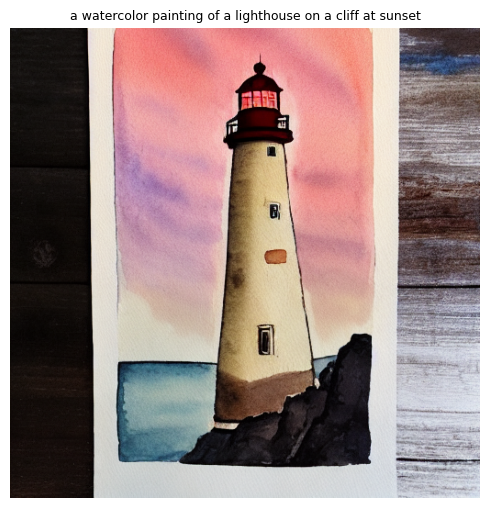

In [10]:
# Empty list that denoise() fills with each step's estimate of the clean latent (used in the next figure).
previews = []
# Wait for any queued GPU work to finish, then start the timer, so the timing covers only this generation.
sync(); t0 = time.perf_counter()
# Start from seeded noise (seed 0) and run 30 DDIM steps with guidance 7.5 to get the clean latent z_0.
z_final = denoise(initial_noise([0]), PROMPT, steps=30, guidance=7.5, previews=previews)
# Decode the clean latent to a 512 x 512 image in [-1, 1] and run the safety checker.
image = decode(z_final)
# Wait for the GPU to finish before stopping the timer (GPU calls return before the work is done).
sync(); elapsed = time.perf_counter() - t0
# Report the time; each step runs the U-Net on a batch of 2 (with and without the prompt).
print(f"30 DDIM steps x 2 U-Net passes (with and without the prompt) + 1 decode: {elapsed:.1f} s")
# Show the generated image with the prompt as its title.
show_row([image[0]], [PROMPT], size=5)

**Reading the output.** In our run, 30 steps and the decode took 5.0 s. In Lecture 1, 1,000 steps for 16 CIFAR-10 images of 32 × 32 took 56 s. Here the image is 256 times larger in area, yet it takes seconds, because it needs 30 steps instead of 1,000 and each step works on a 64 × 64 latent, not on 512 × 512 pixels. Each step does involve a much bigger U-Net, run twice (with and without the prompt), so not everything is cheaper.

Judge the image against the prompt. There is a lighthouse on dark rocks by the sea, with a pink and violet sunset sky, painted in watercolor. But the model also drew the **paper itself**, lying on a wooden table. "A watercolor painting of…" was read as "a photo of a watercolor painting", a common pattern in web captions. The model follows the statistics of its training captions, not our intention.

As in Lectures 1 and 2, we can watch the model's estimate of the clean result, $\hat z_0$, as sampling proceeds. We decode a few of these estimates.

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


safety checker: 2 image(s) replaced by a blank image


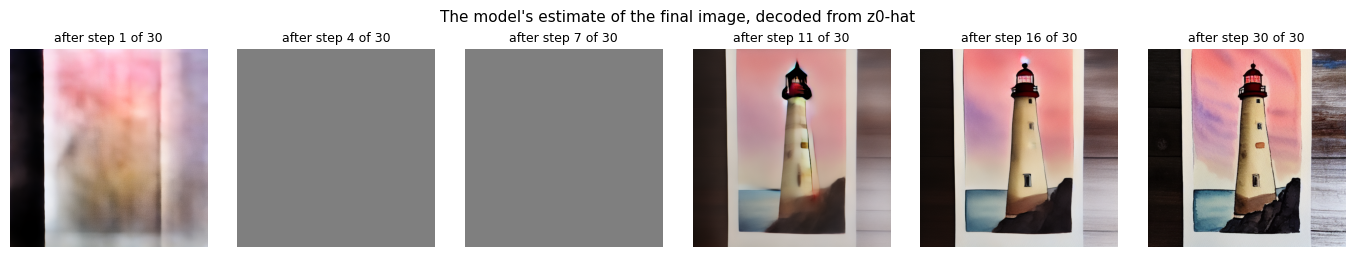

In [11]:
# Indices (0-based) of the 30 DDIM steps whose estimates we want to see: early, middle and the last step.
show_at = [0, 3, 6, 10, 15, 29]
# No gradients are needed, since we only decode.
with torch.no_grad():
    # Stack the chosen estimates of the clean latent (z0-hat), shape (6, 4, 64, 64), and decode them to images.
    preview_images = decode(torch.cat([previews[i] for i in show_at]))
# Show the six decoded estimates in one row, labelled with their step number counted from 1.
show_row(list(preview_images), [f"after step {i + 1} of 30" for i in show_at], size=2.3,
         suptitle="The model's estimate of the final image, decoded from z0-hat")

**Reading the output.**

- **Step 1:** a blur of pink and cream, but with the dark band on the left and the vertical sheet of paper already in place: the **layout** is fixed first.
- **Steps 4 and 7:** grey. The safety checker flagged these two blurry, harmless estimates and replaced them. These are **false positives**: an automatic filter applied to images it was not designed for. The library's pipeline checks only the final image, so it would not have flagged these; our helper checked every decoded image.
- **Step 11:** the complete composition, lighthouse, rocks and sea included.
- **Steps 16 and 30:** sharper edges, texture and the lighthouse's details.

This coarse-to-fine order is the same as in the MNIST and CIFAR-10 trajectories of Lecture 1.

**Is this really what the library does?** A one-line call to the library's pipeline, with the same prompt, seed, sampler, step count and guidance scale, should produce the same image as our loop.

largest pixel difference between our loop and the library pipeline: 0.0005  (pixel range is 2)


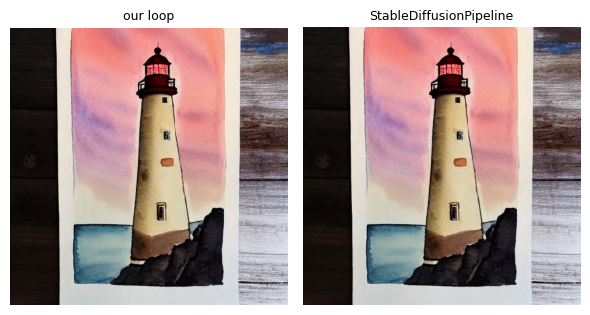

In [12]:
library = pipe(PROMPT, num_inference_steps=30, guidance_scale=7.5,
               generator=torch.Generator(DEVICE).manual_seed(0), output_type="pt").images   # (1, 3, 512, 512) in [0, 1]
library = library.float().cpu() * 2 - 1
print(f"largest pixel difference between our loop and the library pipeline: {(library - image.cpu()).abs().max():.4f}"
      "  (pixel range is 2)")
show_row([image[0], library[0]], ["our loop", "StableDiffusionPipeline"])

**Reading the output.** The largest pixel difference was 0.0005 on a range of 2, invisible in the images. It comes from GPU arithmetic in half precision, the same effect noted for DDIM in Lecture 2. A text-to-image "pipeline" is therefore not a new kind of model. It is this loop: text encoder, noise, guided DDIM steps with a U-Net, decoder.

## 6. The controls: guidance, steps, seed and prompt

Each experiment below changes **one** thing and keeps everything else fixed. Remember from Lecture 2 that DDIM is deterministic: the same seed, prompt and settings give the same image. So any change you see is caused by the setting you changed.

### 6.1 Guidance scale

5 images in 25.7 s


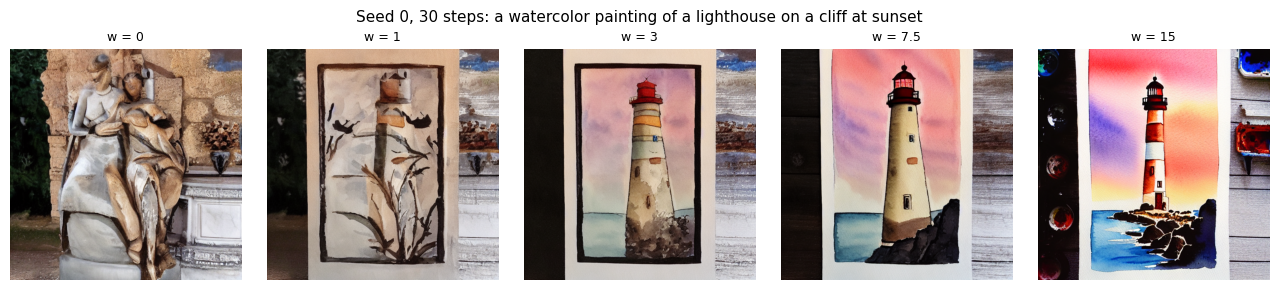

In [13]:
guidance_values = [0, 1, 3, 7.5, 15]
sync(); t0 = time.perf_counter()
images = [text_to_image(PROMPT, seeds=[0], guidance=w)[0] for w in guidance_values]
sync(); print(f"{len(guidance_values)} images in {time.perf_counter() - t0:.1f} s")
show_row(images, [f"w = {w}" for w in guidance_values], size=2.6, suptitle=f"Seed 0, 30 steps: {PROMPT}")

**Reading the output.** The five images took 25.7 s together. They show the trend Lecture 2 measured on digits:

- **$w = 0$** ignores the prompt. From this noise the model drew a stone sculpture of two figures: nothing to do with lighthouses.
- **$w = 1$** uses the prompt without amplification. The result is a muddled sketch, a lighthouse-like shape among brush strokes and branches.
- **$w = 3$** gives a recognisable watercolor lighthouse by the sea, with soft colours.
- **$w = 7.5$** is the image from Section 5: clean and close to the prompt.
- **$w = 15$** is oversaturated: a red-and-white striped lighthouse, a vivid sky, and paint pots creeping in at the edges. The image is pushed so far towards "what the prompt looks like" that it starts to look artificial.

This is the fidelity–diversity trade-off of Lecture 2. Diversity is harder to see with one seed; Section 6.3 varies the seed.

### 6.2 Number of steps

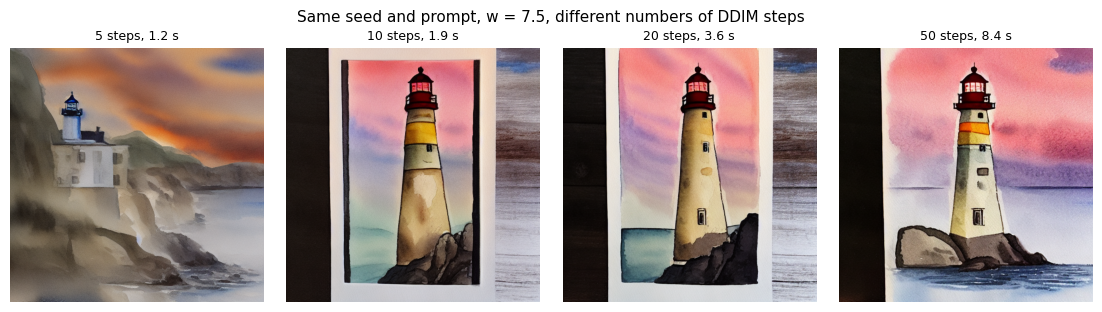

In [14]:
step_counts = [5, 10, 20, 50]
times, images = [], []
for steps in step_counts:
    sync(); t0 = time.perf_counter()
    images.append(text_to_image(PROMPT, seeds=[0], steps=steps)[0])
    sync(); times.append(time.perf_counter() - t0)
show_row(images, [f"{s} steps, {t:.1f} s" for s, t in zip(step_counts, times)], size=2.8,
         suptitle="Same seed and prompt, w = 7.5, different numbers of DDIM steps")

**Reading the output.**

- **Time:** 5, 10, 20 and 50 steps took 1.2, 1.9, 3.6 and 8.4 s. That is about 0.16 s per step plus a fixed cost of under half a second, mostly the decoder.
- **10 and 20 steps** give nearly the same picture as the 30-step image of Section 5: the same lighthouse, sheet of paper and table.
- **5 steps** gives a **different picture**: a misty coastal scene with a small lighthouse on a building, soft and smeared.
- **50 steps** gives the same subject in a different arrangement: a lighthouse on a rock in the sea.

So, unlike the digits of Lecture 2, the composition here is **not** fixed by the seed alone. DDIM is deterministic, but its path depends on which time steps it visits. A large model with many possible pictures can end up at a different one when those steps change. In practice, 20–50 steps is the usual range for this model, and the "best" count depends on the image.

### 6.3 Seed

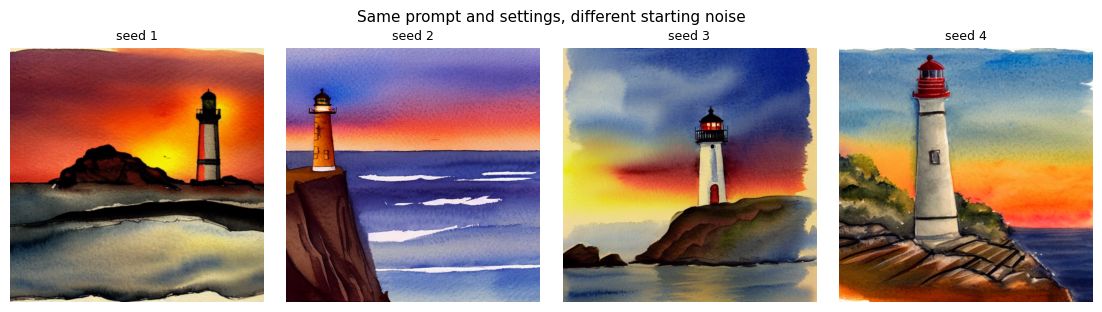

In [15]:
seeds = [1, 2, 3, 4]
images = text_to_image(PROMPT, seeds=seeds)                     # one batch of four
show_row(list(images), [f"seed {s}" for s in seeds], size=2.8, suptitle="Same prompt and settings, different starting noise")

**Reading the output.** The prompt fixes **what** should be there; the starting noise decides **how**. The four seeds give four different pictures that all fit the prompt:

- a lighthouse silhouetted against a red sunset;
- an orange lighthouse on a cliff edge above a blue sea;
- a white lighthouse on a rocky island under a dramatic sky;
- a close view of a lighthouse on rocks.

None of them shows the "painting on a table" framing of seed 0, so that was one seed's interpretation, not a fixed habit of the model. This variety is the model's diversity.

### 6.4 One word at a time

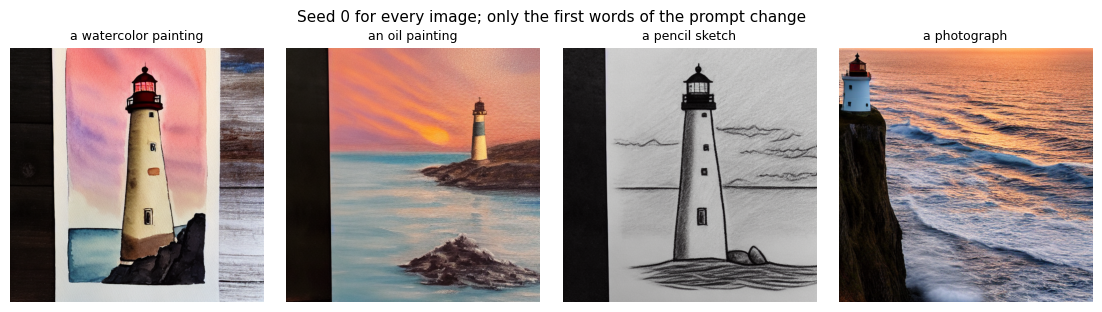

In [16]:
styles = ["a watercolor painting", "an oil painting", "a pencil sketch", "a photograph"]
prompts = [f"{s} of a lighthouse on a cliff at sunset" for s in styles]
images = text_to_image(prompts, seeds=[0] * len(prompts))       # same starting noise for all four
show_row(list(images), styles, size=2.8, suptitle="Seed 0 for every image; only the first words of the prompt change")

**Reading the output.** With the starting noise fixed, changing the style words changed the rendering, and sometimes the layout too:

- **The watercolor and the pencil sketch** share the layout: a sheet of paper on the left, a tall lighthouse in the centre.
- **The oil painting** has a small, distant lighthouse at sunset.
- **The photograph** shows a lighthouse on a cliff above waves.

The starting noise influences the picture, but the prompt can override it. This is the text counterpart of Lecture 2's "same noise, different labels" grid, with a much weaker link between noise and layout.

### 6.5 Negative prompt

The "unconditional" half of guidance does not have to be the empty prompt. If we encode another text there, guidance pushes **away** from it, because $\hat\epsilon = \hat\epsilon_{\text{neg}} + w(\hat\epsilon_{\text{text}} - \hat\epsilon_{\text{neg}})$ moves along the direction from "negative" to "prompt". This is called a **negative prompt**.

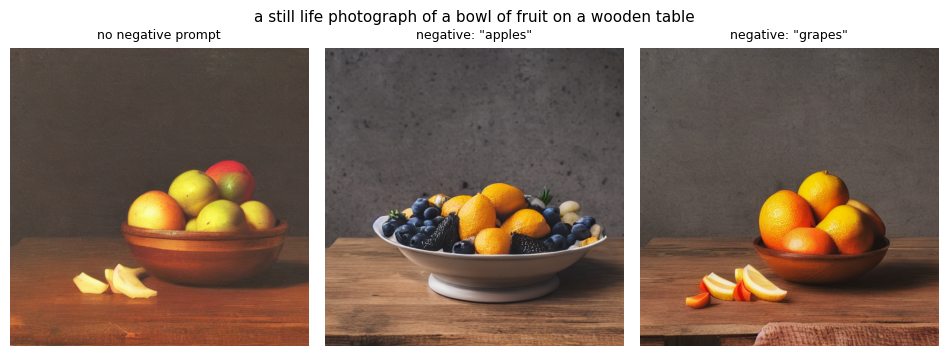

In [17]:
FRUIT = "a still life photograph of a bowl of fruit on a wooden table"
negatives = ["", "apples", "grapes"]
images = [text_to_image(FRUIT, seeds=[5], negative=neg)[0] for neg in negatives]
show_row(images, [f'negative: "{neg}"' if neg else "no negative prompt" for neg in negatives], size=3.2,
         suptitle=FRUIT)

**Reading the output.**

- **Without a negative prompt,** the bowl holds apples and pears, with slices on the table.
- **With "apples" as the negative,** there are no apples. But the bowl, the background and the lighting all changed too: a white bowl of oranges and blueberries in front of a grey wall.
- **With "grapes" as the negative,** the image has oranges in a brown bowl. There were no grapes to remove, yet the picture still changed completely.

A negative prompt is a push, not a filter: it changes the whole guidance direction, so every part of the image can change.

## 7. Editing an existing image (SDEdit)

The forward process gives us a simple way to edit a picture, introduced as **SDEdit** by Meng et al. (2022) and offered by libraries as "image-to-image":

1. Encode the photograph to a latent $z_0$.
2. Add noise **part of the way** up the schedule, to some step $t_{\text{start}}$, using the forward equation.
3. Run the guided reverse process **from $t_{\text{start}}$** with a new prompt.

The **strength** (between 0 and 1) says how far up the noise ladder we go. Low strength keeps most of the original, so the prompt can only change colours and texture. High strength destroys more of it, so the prompt can change shapes, at the cost of faithfulness to the original. At strength 1 the photograph is almost entirely replaced by noise.

We use the CC0 coffee photograph from Section 3. Editing photographs of real people raises the consent and misuse issues discussed in Section 8.

strength 0.3: noise to t = 265, then 9 denoising steps
strength 0.5: noise to t = 463, then 15 denoising steps
strength 0.7: noise to t = 661, then 21 denoising steps
strength 0.9: noise to t = 859, then 27 denoising steps


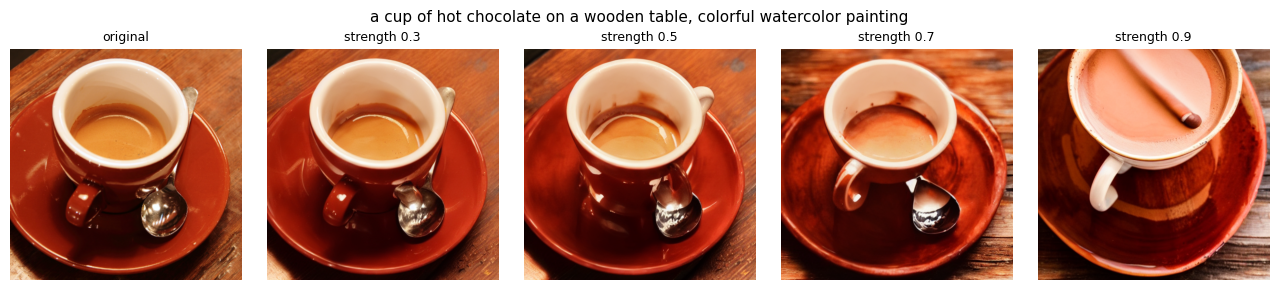

In [18]:
@torch.no_grad()
def edit_image(x, prompt, strength, steps=30, guidance=7.5, seed=0):
    z0 = vae.encode(x).latent_dist.mean * SCALE
    scheduler.set_timesteps(steps, device=DEVICE)
    start = steps - int(steps * strength)                       # skip the noisiest steps
    t_start = scheduler.timesteps[start]
    z_t = scheduler.add_noise(z0, initial_noise([seed]), t_start.reshape(1))   # forward process to t_start
    print(f"strength {strength}: noise to t = {int(t_start)}, then {steps - start} denoising steps")
    return decode(denoise(z_t, prompt, steps=steps, guidance=guidance, start=start))[0]


EDIT_PROMPT = "a cup of hot chocolate on a wooden table, colorful watercolor painting"
strengths = [0.3, 0.5, 0.7, 0.9]
edits = [edit_image(x, EDIT_PROMPT, s) for s in strengths]
show_row([x[0].float()] + edits, ["original"] + [f"strength {s}" for s in strengths], size=2.6, suptitle=EDIT_PROMPT)

**Reading the output.** The printout shows how strength maps to a starting step and to the number of steps run: strength 0.3 noises to $t = 265$ and runs 9 steps; strength 0.9 noises to $t = 859$ and runs 27. Weak edits are faster because fewer steps are run.

- **Strength 0.3 and 0.5:** almost the original photograph, with small changes in highlights and texture.
- **Strength 0.7:** the cup and spoon are reshaped and the drink is paler, while the saucer and table stay.
- **Strength 0.9:** a new picture, a cup of hot chocolate with a stirring stick seen from above. It keeps the red saucer and the warm wood of the original.

None of the edits looks like a watercolor painting. Even at strength 0.9, the starting latent still holds the photograph with weight $\sqrt{\bar\alpha_t} = 0.15$ (at $t = 859$), and that trace was enough to keep the image photographic. The content words of the prompt (hot chocolate) won over the style words.

There is no single correct strength: it is a trade-off between **faithfulness to the input** and **faithfulness to the prompt**, much like the guidance scale trades diversity for prompt fidelity.

Tasks that change only **part** of an image (inpainting) or increase its resolution (super-resolution) use related ideas, but they are not covered in these lectures.

## 8. Limitations and responsible use

### 8.1 Known failure modes

The [model card](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5) lists limitations, including: no legible text, trouble with **compositional** prompts such as "a red cube on top of a blue sphere", imperfect faces and people, and much weaker results for non-English prompts. Let us test three of them.

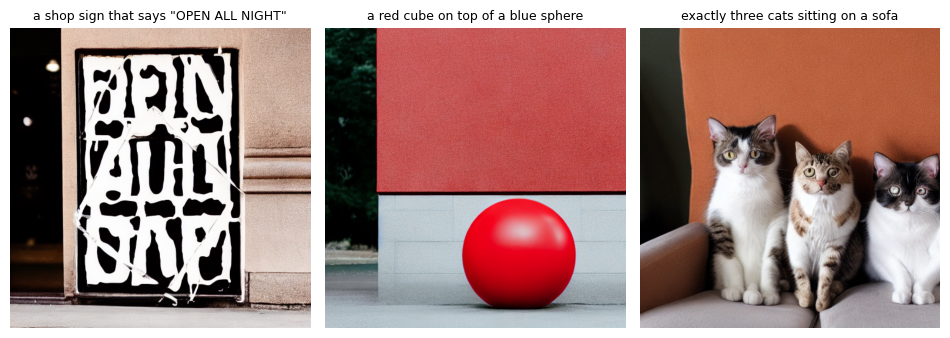

In [19]:
hard_prompts = ['a shop sign that says "OPEN ALL NIGHT"',
                "a red cube on top of a blue sphere",
                "exactly three cats sitting on a sofa"]
images = text_to_image(hard_prompts, seeds=[0] * len(hard_prompts))
show_row(list(images), hard_prompts, size=3.2)

**Reading the output.** Check each image against its prompt word by word.

- **The sign** has letter-like shapes, but they spell nothing.
- **"A red cube on top of a blue sphere"** produced a single red sphere in front of a red wall. There is no cube and nothing blue: the colour "red" and the shape "sphere" were combined, and the rest of the prompt was dropped. This is a failure of **attribute binding**: keeping track of which property belongs to which object.
- **The cats** are exactly three, sitting on a sofa. This time the model succeeded.

One image per prompt is an anecdote. Try two or three other seeds before concluding anything: counting fails often, but not always.

These failures make sense given what you now know about the model:

- The prompt reaches the image only through cross-attention to CLIP vectors, and those vectors are not designed to encode exact spelling, counts, or which attribute belongs to which object.
- The decoder works on 8 × 8 pixel blocks per latent position, which makes small, precise shapes such as letters hard.

### 8.2 Bias: a small probe

The model reproduces patterns in its training data, including social stereotypes. Bianchi et al. (2023) and Luccioni et al. (2023) measured this systematically for Stable Diffusion: prompts that mention only an occupation or a trait produced images skewed towards particular genders and skin tones. The model card also warns that "white and western cultures are often set as the default".

The cell below generates four images for each of two prompts that mention only an occupation.

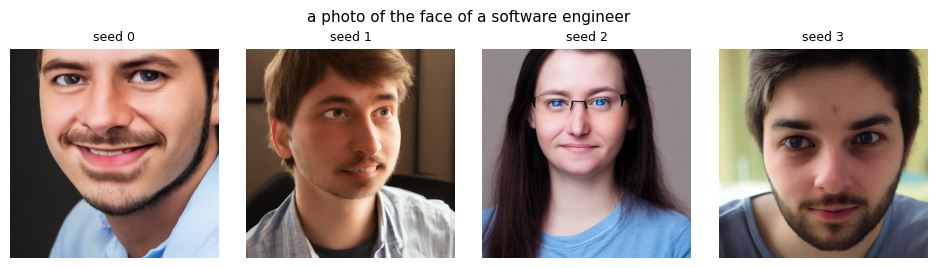

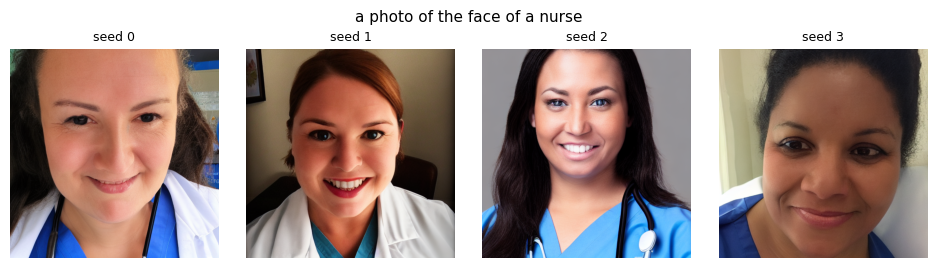

In [20]:
occupations = ["a software engineer", "a nurse"]
for occ in occupations:
    p = f"a photo of the face of {occ}"
    images = text_to_image(p, seeds=[0, 1, 2, 3], steps=25)
    show_row(list(images), [f"seed {s}" for s in range(4)], size=2.4, suptitle=p)

**Reading the output.** In our run, three of the four "software engineer" faces appear to be young men with light skin, and one appears to be a woman with glasses. All four "nurse" faces appear to be women, in scrubs or with stethoscopes. "Appear to be" matters: we are reading gender from a generated face, which is itself an annotation that can be wrong.

Four images per prompt are far too few to **measure** bias, though the pattern matches what the published studies found. That needs hundreds of images per prompt, a careful choice of prompts, and a defensible way to annotate the images, with its own error rate (recall Lecture 2: automatic judges are not ground truth). The published studies above did that work.

Use these images to ask questions, not to answer them: what did the prompt leave unspecified, and what did the model fill in? Would a user who never sees the alternatives notice?

### 8.3 Other questions this model raises

- **Training data and consent.** Stable Diffusion v1 was trained on subsets of LAION-2B(en) (Schuhmann et al., 2022): image–caption pairs collected from the public web. The people and artists in those images were not asked. Training on such data has been challenged in court in more than one country, and the legal position can differ between jurisdictions; check the current position where you work.
- **Memorisation.** The model card states that the training data was not deduplicated and that "we observe some degree of memorization for images that are duplicated in the training data". Carlini et al. (2023) and Somepalli et al. (2023) showed that diffusion models can reproduce some training images almost exactly. This connects to the nearest-neighbour check in Lecture 1.
- **The safety checker is a filter, not a guarantee.** It compares each output with a fixed list of concepts and blanks the matches. It can miss things and it can flag harmless images: in Section 5 it blanked two blurry previews of a lighthouse. Because the code is open, anyone can switch it off. We kept it on.
- **Licence.** The weights are released under the CreativeML OpenRAIL-M licence. It allows use and redistribution but forbids a list of uses (its Attachment A), among them breaking the law, generating false information to harm others, defaming or harassing people, and discriminating against individuals or groups. You are responsible for what you generate. Read the licence before building anything on the model.
- **Misuse.** The editing technique of Section 7 applies to photographs of real people as easily as to a coffee cup. Realistic edited or generated images of real people can deceive and harm. Methods for marking generated content exist, but none is universal or tamper-proof.

## 9. From Lecture 1 to Lecture 3: what changed and what did not

| | Lecture 1 (MNIST) | Lecture 2 (MNIST) | Lecture 3 (Stable Diffusion v1.5) |
| --- | --- | --- | --- |
| Diffusion runs on | pixels, 1 × 28 × 28 | pixels, 1 × 28 × 28 | autoencoder latents, 4 × 64 × 64 |
| Network predicts | noise $\epsilon$ | noise $\epsilon$ | noise $\epsilon$ |
| Condition | none | class label (11 values with "no label") | prompt → 77 × 768 CLIP vectors |
| How the condition enters | — | added to the time embedding | cross-attention at several resolutions |
| Dropping the condition in training | — | 10% | 10% (model card) |
| Sampler | DDPM, 1,000 steps | DDPM and DDIM | DDIM, 20–50 steps |
| Guidance | — | classifier-free | classifier-free, $w \approx 7.5$ |
| Pixels produced by | the diffusion model | the diffusion model | the decoder, once at the end |

The core idea never changed: **a fixed forward process adds noise, and a network trained to predict that noise reverses it one step at a time.** Everything else is engineering that makes that idea cheaper (latents, DDIM) and controllable (conditioning, guidance).

### Common misconceptions

- **"The text encoder draws the image."** It only produces vectors. The U-Net generates the latent, and the decoder turns it into pixels.
- **"The latent is a small, blurry version of the image."** Its channels are not colours, and only the decoder can interpret it (Section 3).
- **"Latent diffusion generates pixels directly."** The diffusion model never sees a pixel. The pixels come from one decoder call at the end.
- **"Higher guidance is always better."** Too much guidance oversaturates and reduces variety (Section 6.1).
- **"If a word is in the prompt, it will be in the image."** Cross-attention makes the text available; it does not enforce it (Section 8.1).

## 10. Summary

| Idea | In one line |
| --- | --- |
| Latent diffusion | Run the diffusion process on an autoencoder's latent (48× fewer values here), decode to pixels once at the end |
| Autoencoder | Encoder: image → latent; decoder: latent → image; lossy, so it caps the final detail |
| Scaling factor | Rescales the latent to roughly unit standard deviation, the scale the diffusion process assumes |
| Text encoder | CLIP turns the prompt into 77 vectors of 768 numbers; longer prompts are cut off |
| Cross-attention | Image positions (queries) take a weighted average of text vectors (keys and values) |
| Sampling loop | Noise → guided DDIM steps with the U-Net → decoder → safety check |
| Guidance, steps, seed | Prompt fidelity vs naturalness and variety; quality vs time; which image among many |
| SDEdit | Noise a real image's latent part of the way, then denoise with a new prompt; strength sets the balance |
| Limits | Text, counting and attribute binding fail often; biases and memorisation come from the training data |

## 11. Check your understanding

1. A 768 × 768 image is encoded with the same autoencoder. What is the shape of its latent, and how many times fewer values does it have than the image?
2. Why is the latent multiplied by a scaling factor before diffusion? What would go wrong if the latent's standard deviation were much larger than 1?
3. The decoder turned random noise into texture rather than a picture. What does that tell you about the division of work between the autoencoder and the diffusion model?
4. In the conditional MNIST model of Lecture 2 the label was added to the time embedding. Why is that not enough for a prompt? What does cross-attention provide instead?
5. In cross-attention, which tensor comes from the image and which from the text? With 4,096 image positions and 77 text positions, what is the shape of the attention-weight matrix?
6. Write the guidance formula with a negative prompt. Why does the negative prompt act as a "push away" rather than a filter?
7. Our hand-written loop and the library pipeline gave (nearly) the same image. Which shared settings made that possible? Which one change would make them differ completely?
8. In SDEdit, what does strength 0.3 do compared with strength 0.9, in terms of the forward process from Lecture 1? Why are low-strength edits faster?
9. Give two reasons, based on how the model works, why "a red cube on top of a blue sphere" is hard for it.
10. A classmate shows four images from the prompt "a photo of the face of a CEO" and concludes that the model is (or is not) biased. What would a convincing study need?
11. In Section 6.2, 5 steps and 50 steps gave different pictures from 10, 20 and 30 steps, while in Lecture 2 the MNIST digits barely changed with the step count. DDIM is deterministic in both cases. What changes when the step count changes, and why might a large text-to-image model be more sensitive to it?
12. **Exercise.** Choose your own prompt. Find a guidance scale and a step count that you think give the best trade-off between quality, variety and time, using at least four seeds per setting. Report your choice and the evidence for it.

## References

- Bianchi, F., Kalluri, P., Durmus, E., Ladhak, F., Cheng, M., Nozza, D., et al. (2023). Easily accessible text-to-image generation amplifies demographic stereotypes at large scale. *FAccT 2023*. [arXiv:2211.03759](https://arxiv.org/abs/2211.03759)
- Carlini, N., Hayes, J., Nasr, M., Jagielski, M., Sehwag, V., Tramèr, F., et al. (2023). Extracting training data from diffusion models. *USENIX Security 2023*. [arXiv:2301.13188](https://arxiv.org/abs/2301.13188)
- Ho, J., Jain, A., & Abbeel, P. (2020). Denoising diffusion probabilistic models. *NeurIPS 2020*. [arXiv:2006.11239](https://arxiv.org/abs/2006.11239)
- Ho, J., & Salimans, T. (2022). Classifier-free diffusion guidance. [arXiv:2207.12598](https://arxiv.org/abs/2207.12598) (first presented at the NeurIPS 2021 Workshop on Deep Generative Models).
- Kingma, D. P., & Welling, M. (2014). Auto-encoding variational Bayes. *ICLR 2014*. [arXiv:1312.6114](https://arxiv.org/abs/1312.6114)
- Lin, S., Liu, B., Li, J., & Yang, X. (2023). Common diffusion noise schedules and sample steps are flawed. [arXiv:2305.08891](https://arxiv.org/abs/2305.08891)
- Luccioni, A. S., Akiki, C., Mitchell, M., & Jernite, Y. (2023). Stable bias: Analyzing societal representations in diffusion models. *NeurIPS 2023 Datasets and Benchmarks*. [arXiv:2303.11408](https://arxiv.org/abs/2303.11408)
- Meng, C., He, Y., Song, Y., Song, J., Wu, J., Zhu, J.-Y., & Ermon, S. (2022). SDEdit: Guided image synthesis and editing with stochastic differential equations. *ICLR 2022*. [arXiv:2108.01073](https://arxiv.org/abs/2108.01073)
- Radford, A., Kim, J. W., Hallacy, C., Ramesh, A., Goh, G., Agarwal, S., et al. (2021). Learning transferable visual models from natural language supervision (CLIP). *ICML 2021*. [arXiv:2103.00020](https://arxiv.org/abs/2103.00020)
- Rombach, R., Blattmann, A., Lorenz, D., Esser, P., & Ommer, B. (2022). High-resolution image synthesis with latent diffusion models. *CVPR 2022*. [arXiv:2112.10752](https://arxiv.org/abs/2112.10752)
- Schuhmann, C., Beaumont, R., Vencu, R., Gordon, C., Wightman, R., Cherti, M., et al. (2022). LAION-5B: An open large-scale dataset for training next generation image-text models. *NeurIPS 2022 Datasets and Benchmarks*. [arXiv:2210.08402](https://arxiv.org/abs/2210.08402)
- Somepalli, G., Singla, V., Goldblum, M., Geiping, J., & Goldstein, T. (2023). Diffusion art or digital forgery? Investigating data replication in diffusion models. *CVPR 2023*. [arXiv:2212.03860](https://arxiv.org/abs/2212.03860)
- Song, J., Meng, C., & Ermon, S. (2021). Denoising diffusion implicit models. *ICLR 2021*. [arXiv:2010.02502](https://arxiv.org/abs/2010.02502)
- Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., et al. (2017). Attention is all you need. *NeurIPS 2017*. [arXiv:1706.03762](https://arxiv.org/abs/1706.03762)
- Model: [`stable-diffusion-v1-5/stable-diffusion-v1-5`](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5) model card and CreativeML OpenRAIL-M licence (a mirror of the original Runway/CompVis release). Library: Hugging Face [`diffusers`](https://github.com/huggingface/diffusers).